In [ ]:
#code 
#sara costa 30_04_2025
#data: neck 
#fig4_b
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [11]:
activity_matrix = pd.read_csv("example_vcf_per_cell/Assignment_Solution/Activities/Assignment_Solution_Activities.txt", sep="\t", index_col=0)


In [ ]:
region_label_map = {
    "neck15": "Normal laryngeal mucosal epithelia (N)",
    "neck17": "Margins of cancer (R)",
    "neck18": "Carcinoma in situ (T)",
    "neck16": "Lymph nodes metastasis (L)"
}

In [15]:
# Extract region code from cell names
activity_matrix["region"] = (
    activity_matrix.index
    .astype(str)
    .str.extract(r"(neck1[5-8])", expand=False)
)

# Map to descriptive labels
activity_matrix["region"] = activity_matrix["region"].map(region_label_map)



In [17]:
activity_matrix["SBS32_active"] = activity_matrix["SBS32"] > 0


In [18]:
overall_summary = pd.DataFrame({
    "percent_cells_SBS32_active": [
        100 * activity_matrix["SBS32_active"].mean()
    ],
    "average_SBS32": [
        activity_matrix["SBS32"].mean()
    ]
})

overall_summary


,percent_cells_SBS32_active,average_SBS32
0,45.722682,33.228498


In [19]:
region_summary = (
    activity_matrix
    .groupby("region")
    .agg(
        percent_cells_SBS32_active=("SBS32_active", lambda x: 100 * x.mean()),
        average_SBS32=("SBS32", "mean"),
        n_cells=("SBS32", "size")
    )
    .reset_index()
)

region_summary


,region,percent_cells_SBS32_active,average_SBS32,n_cells
0,Carcinoma in situ (T),30.337962,22.370797,22902
1,Lymph nodes metastasis (L),80.645919,59.162654,8515
2,Margins of cancer (R),35.290076,25.558855,13100
3,Normal laryngeal mucosal epithelia (N),62.203302,44.262728,11628


In [20]:
overall_row = pd.DataFrame({
    "region": ["overall"],
    "percent_cells_SBS32_active": [100 * activity_matrix["SBS32_active"].mean()],
    "average_SBS32": [activity_matrix["SBS32"].mean()],
    "n_cells": [len(activity_matrix)]
})

combined_summary = pd.concat(
    [overall_row, region_summary],
    ignore_index=True
)

combined_summary


,region,percent_cells_SBS32_active,average_SBS32,n_cells
0,overall,45.722682,33.228498,56145
1,Carcinoma in situ (T),30.337962,22.370797,22902
2,Lymph nodes metastasis (L),80.645919,59.162654,8515
3,Margins of cancer (R),35.290076,25.558855,13100
4,Normal laryngeal mucosal epithelia (N),62.203302,44.262728,11628


In [21]:
region_summary = (
    activity_matrix
    .groupby(["region"])
    .apply(
        lambda df: pd.Series({
            "percent_cells_SBS32_active": 100 * df["SBS32_active"].mean(),
            "average_SBS32_all_cells": df["SBS32"].mean(),
            "average_SBS32_nonzero": df.loc[df["SBS32"] > 0, "SBS32"].mean(),
            "n_cells": len(df),
            "n_cells_SBS32_active": (df["SBS32"] > 0).sum()
        })
    )
    .reset_index()
)

region_summary


/var/folders/vk/dtlt9gqj65jgqz1x4dntcc8nf9q_g9/T/ipykernel_38483/3265269390.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,region,percent_cells_SBS32_active,average_SBS32_all_cells,average_SBS32_nonzero,n_cells,n_cells_SBS32_active
0,Carcinoma in situ (T),30.337962,22.370797,73.738630,22902.0,6948.0
1,Lymph nodes metastasis (L),80.645919,59.162654,73.361002,8515.0,6867.0
2,Margins of cancer (R),35.290076,25.558855,72.425049,13100.0,4623.0
3,Normal laryngeal mucosal epithelia (N),62.203302,44.262728,71.158164,11628.0,7233.0


In [23]:
import matplotlib.pyplot as plt

# Keep only SBS32-positive cells
plot_df = activity_matrix.loc[activity_matrix["SBS32"] > 0].copy()

# Ensure consistent region order
region_order = [
    "Normal laryngeal mucosal epithelia (N)",
    "Margins of cancer (R)",
    "Carcinoma in situ (T)",
    "Lymph nodes metastasis (L)"
]

data = [
    plot_df.loc[plot_df["region"] == r, "SBS32"].values
    for r in region_order
]


In [24]:
import os
from ete3 import Tree
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy.io import mmread

# =============================================================================
# 0. Global figure settings
# =============================================================================

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Arial'

# Make results folder
os.makedirs("results", exist_ok=True)

In [26]:
region_order = ["N", "R", "T", "L"]

/var/folders/vk/dtlt9gqj65jgqz1x4dntcc8nf9q_g9/T/ipykernel_38483/4129435613.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(


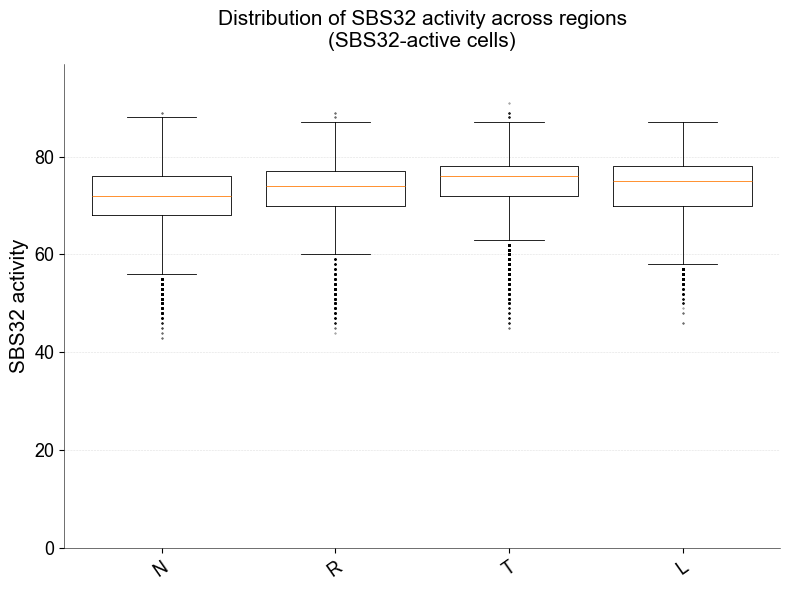

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))

positions = np.arange(len(data)) * 0.25 # <--- spacing factor (smaller = closer)


ax.boxplot(
    data,
    positions=positions,
    labels=region_order,
    showfliers=True,
    patch_artist=False,
    widths=0.2,
    boxprops=dict(linewidth=0.6),
    whiskerprops=dict(linewidth=0.6),
    capprops=dict(linewidth=0.6),
    medianprops=dict(linewidth=0.6),
    flierprops=dict(
        marker="o",
        markersize=0.5,
        alpha=0.5
    ),
)

ax.set_ylabel("SBS32 activity", fontsize=15)
ax.set_title(
    "Distribution of SBS32 activity across regions\n(SBS32-active cells)",
    fontsize=15,
    pad=12
)

ax.tick_params(axis="x", rotation=35, labelsize=13)
ax.tick_params(axis="y", labelsize=13)

ax.set_ylim(0, 99)
ax.set_xlim(positions[0] - 0.14, positions[-1] + 0.14)


# Clean up spines (very common in papers)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(0.4)
ax.spines["left"].set_linewidth(0.4)

# Optional: light horizontal grid only
#ax.set_yticks(np.arange(0, 100, 10))
ax.grid(axis="y", linestyle="--", linewidth=0.4, alpha=0.4)

plt.tight_layout()

plt.savefig(
    "SBS32_activity_boxplots.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()
